### Make a temporary space in /flash

In [1]:
import os, random, string

In [2]:
cwd = os.path.basename(os.getcwd())
tmpdir = os.path.join("/flash/ReiterU/tmp/", 'tomo_' + ''.join(random.choices(string.ascii_uppercase, k=12)))
print(tmpdir)
if not os.path.exists(tmpdir):
    os.makedirs(tmpdir)

/flash/ReiterU/tmp/tomo_VQCQOSMNIROC


### Main

In [13]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from scipy import ndimage as ndi
from nptdms import TdmsFile
from scipy import signal
import h5py
import glob, os
import cv2
from roifile import roiread
from scipy.signal import medfilt2d
from scipy.ndimage import gaussian_filter, gaussian_filter1d
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar

In [4]:
from matplotlib import font_manager
import matplotlib as mpl
font_manager.fontManager.addfont('/bucket/ReiterU/common/fonts/arial.ttf')
mpl.rcParams.update({
    'font.size': 7,
    'axes.titlesize': 7,
    'legend.fontsize': 7,
    'font.family': 'sans-serif',
    'font.sans-serif': "Arial",
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.linewidth': 0.5,
    'xtick.major.width': 0.5,
    'xtick.major.size': 2,
    'xtick.minor.size': 2,
    'xtick.minor.width': 0.5,
    'ytick.major.width': 0.5,
    'ytick.minor.width': 0.5,
    'ytick.major.size': 2,
    'ytick.minor.size': 2,
})

In [5]:
#### path to relevant files
# raw_imagefile = "/bucket/ReiterU/OLdev/experiments/20241022_squid_cal520/2P/rec8/mcorr_nonrigid_denoised/denoised.h5"
# roidir = "/bucket/ReiterU/OLdev/experiments/20241022_squid_cal520/2P/rec8/ROI_corrected"
# dfffile = "/bucket/ReiterU/OLdev/experiments/20241022_squid_cal520/2P/rec8/dff_ROI_corrected/raw/DFF.hdf5"
templatefile = "/bucket/ReiterU/OLdev/experiments/20250317_squid_cal520/2P/rec6/run1/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
syncfile = "/bucket/ReiterU/OLdev/experiments/20250317_squid_cal520/sync/rec6.tdms"
roifile = "/bucket/ReiterU/OLdev/experiments/20250317_squid_cal520/2P/rec6/ROI_yutaka_renamed.zip"
# lsn_matrix_file = "/bucket/ReiterU/OLdev/experiments/visual_stim/20241021_LSN_matrix/LSN_2DEG.npy"
#drg_table = "/bucket/ReiterU/OLdev/experiments/20240820_squid_cal520/psychopy/log_squid1_rec6_DRG_cycle0.csv"

### Load TDMS file

In [6]:
f = TdmsFile.read(syncfile)
g = f.groups()
twop = g[0].channels()[0][:] # line0; TTL generated by 2P scope
cam = g[0].channels()[1][:] # line1; TTL from basler camera
vis = g[0].channels()[2][:] # line2; TTL from Psychopy
print(twop.shape)

twop_re = np.flatnonzero((twop[:-1] < 0.5) & (twop[1:] > 0.5))
print("Rising edges (2P)", twop_re.shape)
cam_re = np.flatnonzero((cam[:-1] < 0.5) & (cam[1:] > 0.5))
print("Rising edges (cam)", cam_re.shape)
vis_re = np.flatnonzero((vis[:-1] < 0.5) & (vis[1:] > 0.5))
print("Rising edges (pyschopy", vis_re.shape)

# reduce to 1 kHz
twop = twop[::5]
cam = cam[::5]
vis = vis[::5]

twop_re = (twop_re / 5).astype("int")
cam_re = (cam_re / 5).astype("int")
vis_re = (vis_re / 5).astype("int")

(6190000,)
Rising edges (2P) (18851,)
Rising edges (cam) (148490,)
Rising edges (pyschopy (1240,)


### Load DF/F

In [7]:
with h5py.File("/bucket/ReiterU/OLdev/experiments/20250317_squid_cal520/2P/rec6/dff_ROI_yutaka/DFF.hdf5", "r") as hf:
    Y = hf["dff"][:]
print(Y.shape)

(276, 1238000)


In [20]:
CELLS = [27, 36, 41, 49, 73, 119, 131, 157, 199, 216, 253]

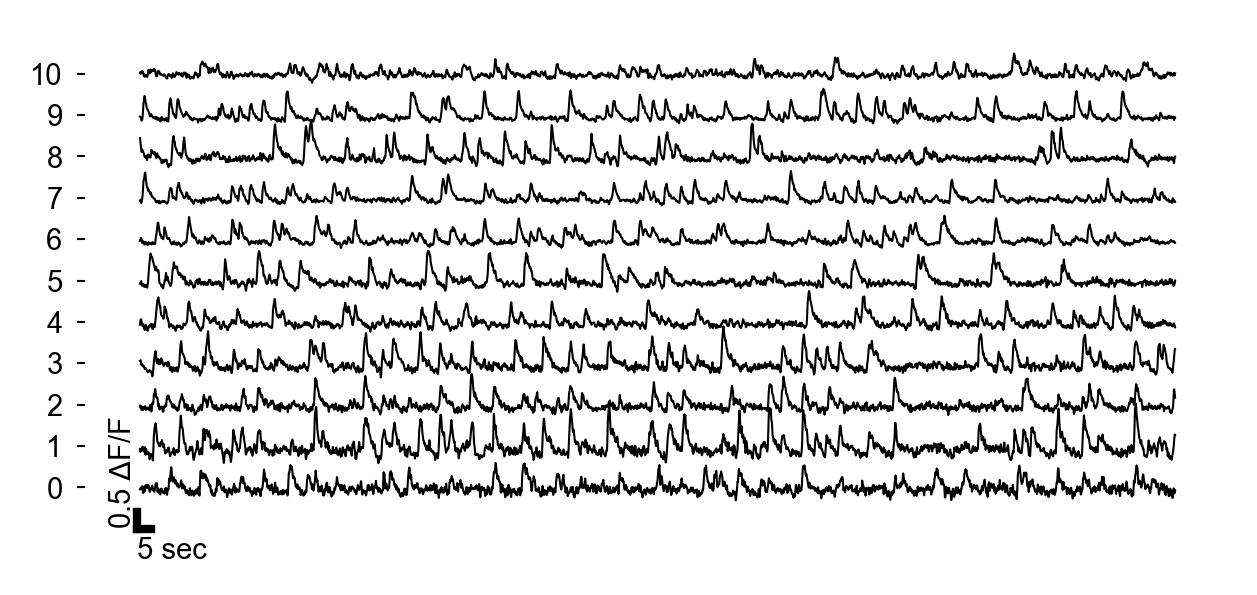

In [65]:
fig, ax = plt.subplots(figsize=(4.2,2), dpi=300)

for (k, i) in enumerate(CELLS):
    smoothed = gaussian_filter1d(Y[i, vis_re[401]:vis_re[800]:50], 2)
    smoothed = smoothed - np.mean(smoothed)
    smoothed = smoothed * 0.8 + k
    t = np.arange(smoothed.size) * 1e-3 * 50
    ax.plot(t, smoothed, color="k", lw=0.5)
# ax.axis("off")
ax.set_yticks(np.arange(len(CELLS)))
ax.set_xticks([])
for sp in ["top", "right", "bottom", "left"]:
    ax.spines[sp].set_visible(False)
    
# Draw the scale bar
ax.plot([-1,-1], [-1, -1 + 0.5* 0.8], color='k', lw=2)
ax.text(-1, -1, '0.5 $\mathrm{\Delta}$F/F', color='k', ha='right', va='bottom', rotation=90)
ax.plot([-1, 4], [-1, -1], color='k', lw=2)
ax.text(-1, -1.2, '5 sec', color='k', ha='left', va='top', rotation=0)

plt.tight_layout()
plt.savefig(os.path.join(tmpdir, 'calcium_trace.pdf'), bbox_inches='tight')
plt.show()

In [22]:
template = cv2.imread(templatefile, -1)

In [23]:
rois = roiread(roifile)
rois = sorted(rois, key=lambda x: x.name)  # sort the list
contours = [r.subpixel_coordinates.astype("int") for r in rois]
coms = [r.subpixel_coordinates.mean(axis=0) for r in rois]

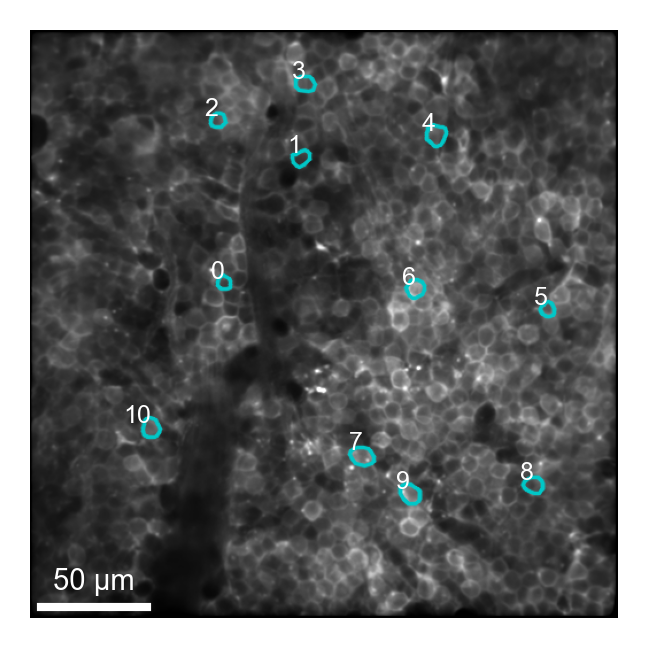

In [31]:
img = template.copy().astype("float")
img = 255 * (img - 10) / (2500 - 100)
img = np.clip(img, 0, 255).astype("uint8")
img = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
for i, c in enumerate(contours):
    if i in CELLS:
        cv2.drawContours(img, contours, contourIdx=i, color=(0,200,200), thickness=2, lineType=cv2.LINE_AA)
        # cv2.putText(img, f"{i}", (int(coms[i][0]), int(coms[i][1])), cv2.FONT_HERSHEY_DUPLEX, 0.5, (255,255,255))

fig = plt.figure(figsize=(1.96,1.96), dpi=300)
ax = fig.add_axes([0, 0, 1, 1])
ax.imshow(img)
for k, i in enumerate(CELLS):
    ax.text(coms[i][0], coms[i][1], f"{k}", color='w', ha='right', va='bottom', fontsize=6)

scalebar = AnchoredSizeBar(ax.transData, 50 / 0.52, '50 µm',
                           'lower left', pad=0.2, color='white',
                           frameon=False, label_top=True, size_vertical=4)
ax.add_artist(scalebar)
ax.axis("off")

plt.savefig(os.path.join(tmpdir, "cell_locations.pdf"))
plt.show()

### Copy data to bucket

In [30]:
savedir = "/bucket/ReiterU/OLdev/analysis/20250420_calcium_method_suppl"
print(f"mkdir -p {savedir}")
print(f"cp -r {tmpdir}/* {savedir}")

mkdir -p /bucket/ReiterU/OLdev/analysis/20250420_calcium_method_suppl
cp -r /flash/ReiterU/tmp/tomo_VQCQOSMNIROC/* /bucket/ReiterU/OLdev/analysis/20250420_calcium_method_suppl
